# Notebook 2 — Inspect and fine-tune Qwen2.5 with LoRA

This hands-on lab uses IEEE iGET 2026 data to explore tokenization, embeddings,
Transformer weights, and parameter-efficient fine-tuning. By completing the lab,
you will inspect model internals, train a LoRA adapter, compare generated answers,
and save and reload the adapter.

The default **memorization experiment** trains on four questions from the supplied
data. Repeated training encourages the model to reproduce their reference answers,
making it possible to observe the effect of fine-tuning on familiar examples.

- GPU: 50 epochs on four examples, batch size 2.
- CPU: 25 epochs on four examples, batch size 1, float32.
- Set `DEMO_MEMORIZATION=False` in section 6 to use the full selected dataset:
  38 training examples on GPU or 16 on CPU.
- Validation data and the common 11-question paraphrase test are evaluated separately.

Run the cells in order. Training time depends on the hardware and number of epochs.
Section 11.2 measures exact recall; repeated training does not guarantee a verbatim
answer. Memorization and generalization are different learning outcomes. For
applications that require current event facts, retrieval-augmented generation (RAG)
provides a way to consult updated sources at inference time.


## 0. Set up the Python environment

Use Python 3.10 or newer in a dedicated environment for this lab. The notebook
uses the Transformers 4.x and TRL 0.29 APIs. It requires `huggingface-hub<1`,
which cannot share an environment with packages that require Hub 1.x, such as
Gradio 6.29 or Diffusers 0.40. Neither Gradio nor Diffusers is used in this lab.

**For local Jupyter or VS Code:** create a separate environment and register its
kernel using the following terminal commands. Select **Qwen LoRA Lab** as the
notebook kernel before running the installation cell.

```sh
python -m venv .venv-qwen-lora
.venv-qwen-lora/bin/python -m pip install ipykernel
.venv-qwen-lora/bin/python -m ipykernel install --user --name qwen-lora-lab --display-name "Qwen LoRA Lab"
```

On Windows, replace `.venv-qwen-lora/bin/python` with
`.venv-qwen-lora\Scripts\python.exe`. Registering a kernel makes it available
to Jupyter; selecting it determines which environment runs the cells.

**For hosted notebooks:** use a dedicated runtime or image compatible with these
dependencies. A fresh hosted runtime may still include conflicting preinstalled
packages. If it reports Hub conflicts, it is not an isolated lab environment;
use a compatible image or a separate Jupyter kernel instead of upgrading Hub alone.

The `%pip` command below installs into the active notebook kernel. It includes
the plotting libraries used later. The lab uses standard LoRA without quantization
and does not require bitsandbytes, Liger, Gradio, or Diffusers.

References: [Transformers 4.57 dependencies](https://github.com/huggingface/transformers/blob/v4.57.6/setup.py),
[TRL 0.29 dependencies](https://github.com/huggingface/trl/blob/v0.29.0/pyproject.toml),
[registering an IPython kernel](https://ipython.readthedocs.io/en/stable/install/kernel_install.html).


In [2]:
%pip install -q "torch>=2.2" "transformers==4.57.6" "huggingface-hub>=0.34,<1" "datasets>=3,<5" "peft==0.18.0" "trl==0.29.0" "accelerate>=1.4,<2" "pandas>=2,<3" "matplotlib>=3.8,<4"


### Check dependencies and restart the kernel

Run the next cell. A consistent environment reports `No broken requirements
found.` If it reports incompatible requirements, select a dedicated compatible
environment and repeat section 0 before continuing. Adding a Hub version pin
makes the lab's requirement explicit; it does not repair incompatible packages
already installed in a shared environment.

After installation, restart the kernel or runtime so imports use the installed
versions. Then continue from section 1. Restarting refreshes imported modules;
it does not resolve conflicting package requirements.


In [3]:
%pip check


ipython 7.34.0 requires jedi, which is not installed.
gradio 6.30.0 has requirement huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2.
diffusers 0.41.0 has requirement huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2.
gradio-client 2.7.2 has requirement huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2.


## 1. Imports and automatic hardware detection


### Verify package versions before loading the model

The next cell checks the installed versions against the versions selected for
this notebook. It also checks already imported modules: installing a package
does not replace Python objects that are still loaded in the current kernel.
If the check fails, rerun the installation in section 0, restart the kernel,
and continue from section 1.

**Troubleshooting an optional `torchao` error:** this lab uses ordinary LoRA on
floating-point weights and does not require torchao quantization. PEFT may still
check that optional package when it is installed. An error asking for torchao
0.16.0 does not match the pinned PEFT 0.18.0 version check. Verify PEFT and restart
after installation rather than changing the LoRA rank, alpha, or dropout.
Upgrading torchao requires checking its compatibility with the installed PyTorch
build; it is not a required setup step for this lab.

Reference: [PEFT 0.18.0 optional-backend checks](https://github.com/huggingface/peft/blob/v0.18.0/src/peft/import_utils.py).


In [4]:
import sys
from importlib.metadata import PackageNotFoundError, version

expected_versions = {
    "transformers": "4.57.6",
    "peft": "0.18.0",
    "trl": "0.29.0",
}
version_problems = []
for package_name, expected_version in expected_versions.items():
    try:
        installed_version = version(package_name)
    except PackageNotFoundError:
        installed_version = "not installed"
    loaded_module = sys.modules.get(package_name)
    loaded_version = getattr(loaded_module, "__version__", None)
    print(f"{package_name}: installed={installed_version}, loaded={loaded_version}, expected={expected_version}")
    if installed_version != expected_version:
        version_problems.append(f"{package_name}: installed {installed_version}, expected {expected_version}")
    if loaded_module is not None and loaded_version != expected_version:
        version_problems.append(f"{package_name}: a different version is still loaded in this kernel")
try:
    print("Optional torchao package:", version("torchao"))
except PackageNotFoundError:
    print("Optional torchao package: not installed (not required for this lab)")
if version_problems:
    raise RuntimeError(
        "Package version mismatch: " + "; ".join(version_problems)
        + ". Run the section 0 installation, restart the kernel, and resume from section 1."
    )


transformers: installed=4.57.6, loaded=None, expected=4.57.6
peft: installed=0.18.0, loaded=None, expected=0.18.0
trl: installed=0.29.0, loaded=None, expected=0.29.0
Optional torchao package: 0.10.0


In [5]:
import os, sys, time, gc
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed
from peft import LoraConfig, get_peft_model, PeftModel
from trl import SFTConfig, SFTTrainer
import transformers, peft, trl
from peft.import_utils import is_torchao_available

# Check optional-backend metadata before downloading or loading the model.
try:
    torchao_available = is_torchao_available()
except ImportError as error:
    raise RuntimeError(
        "PEFT rejected the installed optional torchao package. Verify the pinned "
        "PEFT version in the preceding cell, restart after installation, and "
        "use the dedicated lab environment described in section 0."
    ) from error
print("PEFT optional torchao check passed; detected:", torchao_available)

set_seed(42)

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda" if HAS_GPU else "cpu"
MODE = "GPU" if HAS_GPU else "CPU"

print("Hardware mode:", MODE)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("Device:", DEVICE)

if HAS_GPU:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No CUDA GPU detected. Using CPU-safe settings.")


PEFT optional torchao check passed; detected: True
Hardware mode: GPU
Python: 3.13.15
PyTorch: 2.11.0+cu130
Transformers: 4.57.6
PEFT: 0.18.0
TRL: 0.29.0
Device: cuda
GPU: Tesla T4


## 2. Select CPU or GPU dataset automatically

Place all five supplied `.jsonl` files in the notebook's working directory.
In a hosted notebook environment, upload the files to that directory. The code
selects the training and validation pair for the detected hardware; both modes
use the same test file.


In [7]:
if HAS_GPU:
    TRAIN_FILE = "iget_train_gpu.jsonl"
    VAL_FILE = "iget_validation_gpu.jsonl"
else:
    TRAIN_FILE = "iget_train_cpu.jsonl"
    VAL_FILE = "iget_validation_cpu.jsonl"

TEST_FILE = "iget_test.jsonl"

for p in [TRAIN_FILE, VAL_FILE, TEST_FILE]:
    assert os.path.exists(p), f"Missing file: {p}"

print("Training file:", TRAIN_FILE)
print("Validation file:", VAL_FILE)
print("Test file:", TEST_FILE)


Training file: iget_train_gpu.jsonl
Validation file: iget_validation_gpu.jsonl
Test file: iget_test.jsonl


## 3. Load and inspect data


### 3.1 Validate the supplied data before training

The following cell validates all five files, checks the message roles and text
fields, and reports duplicate questions and exact question overlap between splits.
Training and validation rows contain conversational `prompt`/`completion` lists;
test rows contain questions, reference answers, and keywords for evaluation.
Source fields record provenance and are excluded from the training columns.

The CPU datasets are subsets of the GPU datasets. Questions in the training,
validation, and test splits cover overlapping facts with different wording.
The evaluation therefore measures recall of those facts through paraphrases;
it does not measure knowledge of new facts. This validation reads local files
without fetching the source URLs.


In [8]:
import json
from pathlib import Path

def validate_workshop_rows(filename, is_test=False):
    records = []
    with Path(filename).open(encoding="utf-8") as stream:
        for line_number, line in enumerate(stream, 1):
            location = f"{filename}:{line_number}"
            try:
                record = json.loads(line)
            except json.JSONDecodeError as error:
                raise ValueError(f"{location}: invalid JSON") from error
            if not isinstance(record, dict):
                raise ValueError(f"{location}: expected a JSON object")
            fields = ["source_url"]
            fields += ["question", "expected_answer", "category"] if is_test else ["source_section"]
            for field in fields:
                if not isinstance(record.get(field), str) or not record[field].strip():
                    raise ValueError(f"{location}: missing/non-text {field}")
            if is_test:
                keywords = record.get("expected_keywords")
                if not isinstance(keywords, list) or not keywords or not all(
                    isinstance(word, str) and word.strip() for word in keywords
                ):
                    raise ValueError(f"{location}: expected nonempty keyword strings")
            else:
                for field, role in [("prompt", "user"), ("completion", "assistant")]:
                    messages = record.get(field)
                    if not isinstance(messages, list) or len(messages) != 1:
                        raise ValueError(f"{location}: expected one {field} message")
                    message = messages[0]
                    if not isinstance(message, dict) or message.get("role") != role:
                        raise ValueError(f"{location}: invalid {field} role")
                    if not isinstance(message.get("content"), str) or not message["content"].strip():
                        raise ValueError(f"{location}: missing/non-text {field} content")
            records.append(record)
    if not records:
        raise ValueError(f"{filename}: empty dataset")
    return records

audit_rows = {}
audit_summary = []
for filename in ["iget_train_cpu.jsonl", "iget_validation_cpu.jsonl",
                 "iget_train_gpu.jsonl", "iget_validation_gpu.jsonl", "iget_test.jsonl"]:
    is_test = filename == "iget_test.jsonl"
    records = validate_workshop_rows(filename, is_test=is_test)
    audit_rows[filename] = records
    questions = [row["question"] if is_test else row["prompt"][0]["content"] for row in records]
    normalized = [question.strip().casefold() for question in questions]
    audit_summary.append({"file": filename, "examples": len(records),
                          "duplicate_questions": len(normalized) - len(set(normalized)),
                          "source_pages": len({row["source_url"] for row in records})})
display(pd.DataFrame(audit_summary))

def question_set(records, is_test=False):
    return {(row["question"] if is_test else row["prompt"][0]["content"]).strip().casefold()
            for row in records}

for mode in ["cpu", "gpu"]:
    train_questions = question_set(audit_rows[f"iget_train_{mode}.jsonl"])
    validation_questions = question_set(audit_rows[f"iget_validation_{mode}.jsonl"])
    test_questions = question_set(audit_rows["iget_test.jsonl"], is_test=True)
    print(mode.upper(), "exact question overlaps:",
          {"train/validation": len(train_questions & validation_questions),
           "train/test": len(train_questions & test_questions),
           "validation/test": len(validation_questions & test_questions)})
for split in ["train", "validation"]:
    cpu_subset = all(row in audit_rows[f"iget_{split}_gpu.jsonl"]
                     for row in audit_rows[f"iget_{split}_cpu.jsonl"])
    print(f"CPU {split} is a subset of GPU {split}: {cpu_subset}")


,file,examples,duplicate_questions,source_pages
0,iget_train_cpu.jsonl,16,0,3
1,iget_validation_cpu.jsonl,4,0,2
2,iget_train_gpu.jsonl,38,0,3
3,iget_validation_gpu.jsonl,8,0,3
4,iget_test.jsonl,11,0,3


CPU exact question overlaps: {'train/validation': 0, 'train/test': 0, 'validation/test': 0}
GPU exact question overlaps: {'train/validation': 0, 'train/test': 0, 'validation/test': 0}
CPU train is a subset of GPU train: True
CPU validation is a subset of GPU validation: True


In [9]:
train_raw = load_dataset("json", data_files=TRAIN_FILE, split="train")
val_raw = load_dataset("json", data_files=VAL_FILE, split="train")
test_ds = load_dataset("json", data_files=TEST_FILE, split="train")

train_ds = train_raw.select_columns(["prompt", "completion"])
val_ds = val_raw.select_columns(["prompt", "completion"])

print("Training examples:", len(train_ds))
print("Validation examples:", len(val_ds))
print("Test questions:", len(test_ds))
print("\nExample:")
print(train_raw[0])


Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Training examples: 38
Validation examples: 8
Test questions: 11

Example:
{'prompt': [{'role': 'user', 'content': 'What is the full name of iGET 2026?'}], 'completion': [{'role': 'assistant', 'content': 'iGET 2026 is the 2026 IEEE Global Emerging Technologies Conference.'}], 'source_url': 'https://www.ieee-iget.org/', 'source_section': 'Conference overview'}


## 4. Load Qwen for the detected device


In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

DTYPE = torch.float16 if HAS_GPU else torch.float32

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
)

base_model.to(DEVICE)
base_model.eval()

print("Model dtype:", next(base_model.parameters()).dtype)
print("Model device:", next(base_model.parameters()).device)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model dtype: torch.float16
Model device: cuda:0


### 4.1 From text to token IDs

A token can represent part of a word, a word, punctuation, or whitespace.
Its integer ID selects an embedding row. The following cell tokenizes the first
training question and lists its token IDs alongside their text representations.
`repr` makes spaces and newlines visible; a token's internal spelling may differ
from its decoded text. Individual byte tokens may decode to replacement characters.
Increase `VOCAB_PREVIEW` to inspect more vocabulary entries.


In [11]:
inspection_text = train_ds[0]["prompt"][0]["content"]
inspection_ids = tokenizer.encode(inspection_text, add_special_tokens=False)
print("Text:", inspection_text)
print("Token count:", len(inspection_ids))
print("Round-trip matches:", tokenizer.decode(inspection_ids) == inspection_text)
display(pd.DataFrame([
    {"position": position, "token_id": token_id,
     "token": repr(tokenizer.convert_ids_to_tokens(token_id)),
     "decoded_piece": repr(tokenizer.decode([token_id], skip_special_tokens=False))}
    for position, token_id in enumerate(inspection_ids[:48])
]))

VOCAB_PREVIEW = 20
vocab = tokenizer.get_vocab()
print("Base vocabulary size:", tokenizer.vocab_size)
print("Tokenizer length (including added tokens):", len(tokenizer))
display(pd.DataFrame([
    {"token_id": token_id, "token": repr(token)}
    for token, token_id in sorted(vocab.items(), key=lambda item: item[1])[:VOCAB_PREVIEW]
]))


Text: What is the full name of iGET 2026?
Token count: 14
Round-trip matches: True


,position,token_id,token,decoded_piece
0,0,3838,'What','What'
1,1,374,'Ġis',' is'
2,2,279,'Ġthe',' the'
3,3,2480,'Ġfull',' full'
4,4,829,'Ġname',' name'
5,5,315,'Ġof',' of'
6,6,600,'Ġi',' i'
7,7,3806,'GET','GET'
8,8,220,'Ġ',' '
9,9,17,'2','2'


Base vocabulary size: 151643
Tokenizer length (including added tokens): 151665


,token_id,token
0,0,'!'
1,1,"'""'"
2,2,'#'
3,3,'$'
4,4,'%'
5,5,'&'
6,6,"""'"""
7,7,'('
8,8,')'
9,9,'*'


### 4.2 Beginning, ending, padding, and chat markers

Do not assume every model has a beginning-of-sequence (BOS) token. For this
Qwen2.5 Instruct tokenizer, BOS is normally `None`; `<|im_start|>` starts a chat
**message**, `<|im_end|>` ends one, and `<|endoftext|>` is the padding token.
A message marker is not automatically a BOS token. Read tokenizer, model, and
generation settings separately; generation may have multiple stopping IDs.

The rendered template can add a default system message and an assistant prefix.
Raw text tokenization alone does not show those chat boundaries.


In [12]:
special_rows = []
for label in ["bos", "eos", "pad", "unk"]:
    special_rows.append({"role": label,
                         "token": repr(getattr(tokenizer, f"{label}_token", None)),
                         "token_id": getattr(tokenizer, f"{label}_token_id", None)})
display(pd.DataFrame(special_rows))
display(pd.DataFrame([
    {"special_token": repr(token), "token_id": token_id}
    for token, token_id in zip(tokenizer.all_special_tokens, tokenizer.all_special_ids)
]))
for label in ["bos_token_id", "eos_token_id", "pad_token_id"]:
    print(label, "model:", getattr(base_model.config, label, None),
          "generation:", getattr(base_model.generation_config, label, None))

inspection_messages = [{"role": "user", "content": inspection_text}]
chat_text = tokenizer.apply_chat_template(
    inspection_messages, tokenize=False, add_generation_prompt=True
)
chat_ids = tokenizer.apply_chat_template(
    inspection_messages, tokenize=True, add_generation_prompt=True
)
print("Rendered inference prompt:\n", chat_text)
print("First token:", chat_ids[0], repr(tokenizer.convert_ids_to_tokens(chat_ids[0])))
print("Last prompt token:", chat_ids[-1], repr(tokenizer.convert_ids_to_tokens(chat_ids[-1])))
print("The prompt ends with an assistant prefix, not necessarily EOS.")


,role,token,token_id
0,bos,None,NaN
1,eos,'<|im_end|>',151645.0
2,pad,'<|endoftext|>',151643.0
3,unk,None,NaN


,special_token,token_id
0,'<|im_end|>',151645
1,'<|endoftext|>',151643
2,'<|im_start|>',151644
3,'<|object_ref_start|>',151646
4,'<|object_ref_end|>',151647
5,'<|box_start|>',151648
6,'<|box_end|>',151649
7,'<|quad_start|>',151650
8,'<|quad_end|>',151651
9,'<|vision_start|>',151652


bos_token_id model: 151643 generation: 151643
eos_token_id model: 151645 generation: [151645, 151643]
pad_token_id model: None generation: 151643
Rendered inference prompt:
 <|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
What is the full name of iGET 2026?<|im_end|>
<|im_start|>assistant

First token: 151644 '<|im_start|>'
Last prompt token: 198 'Ċ'
The prompt ends with an assistant prefix, not necessarily EOS.


### 4.3 Inspect embeddings and the output head

The input embedding table has shape `[vocabulary rows, hidden size]`. Looking up
N token IDs produces `[N, hidden size]`; these are learned input vectors, not yet
contextual representations from the Transformer layers. The output head maps
hidden states to vocabulary logits. Some models share these two weight tensors.
Tokenizer length and embedding row count may differ because of unused/padded rows.

Only a few values are copied to CPU for display. No gradients or weights are changed.


In [13]:
input_embedding = base_model.get_input_embeddings()
output_head = base_model.get_output_embeddings()
print("Input embedding:", input_embedding)
print("Embedding weight shape:", tuple(input_embedding.weight.shape))
print("Output head weight shape:", tuple(output_head.weight.shape))
print("Tied weights:", input_embedding.weight.data_ptr() == output_head.weight.data_ptr())
print("Embedding rows minus tokenizer length:", input_embedding.weight.shape[0] - len(tokenizer))

preview_ids = inspection_ids[:8]
with torch.no_grad():
    token_tensor = torch.tensor(preview_ids, dtype=torch.long, device=input_embedding.weight.device)
    embedding_preview = input_embedding(token_tensor)
    embedding_values = embedding_preview[:, :8].detach().float().cpu()
print("Embedding lookup shape:", tuple(embedding_preview.shape))
embedding_table = pd.DataFrame(embedding_values.numpy(), columns=[f"dim_{i}" for i in range(8)])
embedding_table.insert(0, "token_id", preview_ids)
display(embedding_table)


Input embedding: Embedding(151936, 896)
Embedding weight shape: (151936, 896)
Output head weight shape: (151936, 896)
Tied weights: True
Embedding rows minus tokenizer length: 271
Embedding lookup shape: (8, 896)


,token_id,dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7
0,3838,-0.033691,-0.006348,0.013489,-0.021973,-0.003937,-0.000317,-0.002411,-0.006165
1,374,-0.005127,0.015381,-0.005859,-0.000452,-0.008057,0.006592,-0.002502,-0.003387
2,279,0.000713,-0.009583,-0.002060,-0.008545,0.003067,-0.002914,-0.009094,-0.004547
3,2480,-0.002518,0.032471,-0.001938,0.004486,-0.003677,0.004700,-0.005737,0.002869
4,829,-0.004242,-0.002335,-0.009949,0.013672,0.013123,-0.001862,0.015259,0.011902
5,315,-0.003937,0.005310,0.004028,-0.001289,0.009827,-0.009644,0.006561,-0.009155
6,600,0.019775,-0.021973,0.012390,-0.000629,-0.008545,0.010437,0.001732,-0.000690
7,3806,0.014282,0.010071,0.012390,-0.000603,-0.000188,0.008362,0.000265,-0.008118


### 4.4 Architecture and weights before LoRA

Inspect the dimensions and the first attention block. `q_proj` and `v_proj` are
the projections this lab will adapt. Grouped-query attention can give these
projections different output sizes, so inspect their actual shapes.

`eval()` changes dropout behavior; it does **not** freeze parameters. Freshly
loaded floating-point base weights normally have `requires_grad=True`.
PEFT freezes the base weights when we attach LoRA in section 8. The table here
captures the state **before** attachment; section 9 checks it again afterward.


In [14]:
config = base_model.config
for field in ["model_type", "num_hidden_layers", "hidden_size", "intermediate_size",
              "num_attention_heads", "num_key_value_heads", "vocab_size"]:
    print(field, ":", getattr(config, field, None))
print("First attention block:\n", base_model.model.layers[0].self_attn)
before_lora_parameters = [
    {"name": name, "shape": tuple(parameter.shape), "elements": parameter.numel(),
     "requires_grad": parameter.requires_grad, "dtype": str(parameter.dtype)}
    for name, parameter in base_model.named_parameters()
]
display(pd.DataFrame(before_lora_parameters).head(14))
print("Total parameters before LoRA:", sum(p.numel() for p in base_model.parameters()))
print("Trainable before LoRA:", sum(p.numel() for p in base_model.parameters() if p.requires_grad))


model_type : qwen2
num_hidden_layers : 24
hidden_size : 896
intermediate_size : 4864
num_attention_heads : 14
num_key_value_heads : 2
vocab_size : 151936
First attention block:
 Qwen2Attention(
  (q_proj): Linear(in_features=896, out_features=896, bias=True)
  (k_proj): Linear(in_features=896, out_features=128, bias=True)
  (v_proj): Linear(in_features=896, out_features=128, bias=True)
  (o_proj): Linear(in_features=896, out_features=896, bias=False)
)


,name,shape,elements,requires_grad,dtype
0,model.embed_tokens.weight,"(151936, 896)",136134656,True,torch.float16
1,model.layers.0.self_attn.q_proj.weight,"(896, 896)",802816,True,torch.float16
2,model.layers.0.self_attn.q_proj.bias,"(896,)",896,True,torch.float16
3,model.layers.0.self_attn.k_proj.weight,"(128, 896)",114688,True,torch.float16
4,model.layers.0.self_attn.k_proj.bias,"(128,)",128,True,torch.float16
5,model.layers.0.self_attn.v_proj.weight,"(128, 896)",114688,True,torch.float16
6,model.layers.0.self_attn.v_proj.bias,"(128,)",128,True,torch.float16
7,model.layers.0.self_attn.o_proj.weight,"(896, 896)",802816,True,torch.float16
8,model.layers.0.mlp.gate_proj.weight,"(4864, 896)",4358144,True,torch.float16
9,model.layers.0.mlp.up_proj.weight,"(4864, 896)",4358144,True,torch.float16


Total parameters before LoRA: 494032768
Trainable before LoRA: 494032768


### 4.5 Check training lengths with the chat template

Count complete prompt + completion sequences, including chat markers. The initial
sequence-length budgets are 128 tokens on CPU and 256 on GPU. Truncation can remove
part of a reference answer or its end marker, reducing the training signal.
The table identifies sequences that exceed the initial budget; section 10 sets
the actual training limit high enough to preserve all selected training and
validation sequences.

Source metadata is not tokenized. Inference adds an assistant prefix, whereas a
complete training conversation already contains the assistant response.


In [15]:
sequence_limit = 256 if HAS_GPU else 128
length_rows = []
for split_name, dataset in [("train", train_ds), ("validation", val_ds)]:
    for row_index, item in enumerate(dataset):
        token_count = len(tokenizer.apply_chat_template(
            item["prompt"] + item["completion"], tokenize=True, add_generation_prompt=False
        ))
        length_rows.append({"split": split_name, "row": row_index, "tokens": token_count,
                            "over_limit": token_count > sequence_limit})
length_df = pd.DataFrame(length_rows)
display(length_df.groupby("split").agg(examples=("tokens", "size"),
                                      max_tokens=("tokens", "max"),
                                      over_limit=("over_limit", "sum")))
if length_df["over_limit"].any():
    print("Review these rows before training (zero-based indices):")
    display(length_df[length_df["over_limit"]])


,examples,max_tokens,over_limit
split,,,
train,38,85,0
validation,8,73,0


References: [Qwen tokenizer configuration](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct/blob/main/tokenizer_config.json),
[PEFT LoRA](https://huggingface.co/docs/peft/package_reference/lora),
[TRL SFTTrainer](https://huggingface.co/docs/trl/sft_trainer).


## 5. Deterministic inference helper


In [16]:
def ask(model, question, max_new_tokens=128):
    messages = [{"role": "user", "content": question}]
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )
    device = next(model.parameters()).device
    inputs = {key: value.to(device) for key, value in inputs.items()}
    was_training = model.training
    model.eval()
    try:
        with torch.no_grad():
            output = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                num_beams=1,
                use_cache=True,
                eos_token_id=tokenizer.eos_token_id,
                pad_token_id=tokenizer.pad_token_id,
            )
    finally:
        model.train(was_training)
    generated = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated, skip_special_tokens=True).strip()


## 6. Select training examples and capture the baseline

`DEMO_MEMORIZATION=True` selects four existing records about conference dates,
location, the workshop deadline, and the poster-session date. Both CPU and GPU
datasets contain these questions. Set the switch to `False` to train on the full
dataset selected for the detected hardware.

Capture the base model's answers before attaching LoRA. Inference uses the same
question and chat template as training, without including the reference answer
in the generation prompt. Some base-model answers may already match the references;
compare those rows with examples where fine-tuning changes the output.


In [17]:
DEMO_MEMORIZATION = True
DEMO_EPOCHS = 50 if HAS_GPU else 25
DEMO_LEARNING_RATE = 5e-4

baseline_questions = [
    "When will iGET 2026 take place?",
    "Where is iGET 2026 being held?",
    "What is the iGET 2026 workshop proposal deadline?",
    "When is the iGET 2026 poster session?",
]
training_indices = {item["prompt"][0]["content"]: index for index, item in enumerate(train_ds)}
missing_questions = [question for question in baseline_questions if question not in training_indices]
if missing_questions:
    raise ValueError(f"Demo questions missing from selected training data: {missing_questions}")
demo_indices = [training_indices[question] for question in baseline_questions]
demo_examples = train_ds.select(demo_indices)
fit_train_ds = demo_examples if DEMO_MEMORIZATION else train_ds
demo_targets = {item["prompt"][0]["content"]: item["completion"][0]["content"]
                for item in demo_examples}

def normalized_answer(text):
    # Ignore whitespace differences only; preserve punctuation, casing and facts.
    return " ".join(text.split())

baseline_answers = {}
for question in baseline_questions:
    baseline_answers[question] = ask(base_model, question)
display(pd.DataFrame([
    {"question": question, "reference": demo_targets[question],
     "before": baseline_answers[question],
     "before_exact": normalized_answer(baseline_answers[question]) == normalized_answer(demo_targets[question])}
    for question in baseline_questions
]))
print("Memorization mode:", DEMO_MEMORIZATION, "| Actual training examples:", len(fit_train_ds))


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,question,reference,before,before_exact
0,When will iGET 2026 take place?,iGET 2026 will take place from October 21 thro...,"I'm sorry, but I can't assist with that.",False
1,Where is iGET 2026 being held?,"iGET 2026 is being held in Irvine, California.","I'm sorry, but I don't have access to real-tim...",False
2,What is the iGET 2026 workshop proposal deadline?,The workshop proposal deadline listed in the C...,"I apologize for any inconvenience caused, but ...",False
3,When is the iGET 2026 poster session?,The Student Poster Contest poster session and ...,"I apologize for any inconvenience caused, but ...",False


Memorization mode: True | Actual training examples: 4


## 7. Inspect Transformer attention modules


In [18]:
print(base_model.model.layers[0].self_attn)
print("\nq_proj:", base_model.model.layers[0].self_attn.q_proj)
print("\nv_proj:", base_model.model.layers[0].self_attn.v_proj)


Qwen2Attention(
  (q_proj): Linear(in_features=896, out_features=896, bias=True)
  (k_proj): Linear(in_features=896, out_features=128, bias=True)
  (v_proj): Linear(in_features=896, out_features=128, bias=True)
  (o_proj): Linear(in_features=896, out_features=896, bias=False)
)

q_proj: Linear(in_features=896, out_features=896, bias=True)

v_proj: Linear(in_features=896, out_features=128, bias=True)


## 8. Add LoRA

Memorization mode uses rank 16, alpha 32, and zero LoRA dropout. Full-data mode
uses rank 8, alpha 16, and dropout 0.05. Both configurations adapt `q_proj` and
`v_proj`. The random seed is set before the adapter matrices are initialized.


In [19]:
lora_config = LoraConfig(
    r=16 if DEMO_MEMORIZATION else 8,
    lora_alpha=32 if DEMO_MEMORIZATION else 16,
    lora_dropout=0.0 if DEMO_MEMORIZATION else 0.05,
    target_modules=["q_proj", "v_proj"],
    bias="none",
    task_type="CAUSAL_LM",
)

model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()


trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184


## 9. Inspect exactly what LoRA added

Only A/B matrices should be trainable with this configuration; the embedding,
output head, attention base weights, MLP, and normalization weights stay frozen.
`requires_grad=False` prevents gradient updates; it does not remove a weight
from the forward pass. `get_peft_model` wraps the existing base model in place.

### 9.1 Count and list frozen versus trainable parameters


In [20]:
parameter_rows = [
    {"name": name, "shape": tuple(parameter.shape), "elements": parameter.numel(),
     "requires_grad": parameter.requires_grad, "dtype": str(parameter.dtype)}
    for name, parameter in model.named_parameters()
]
parameter_df = pd.DataFrame(parameter_rows)
display(parameter_df.groupby("requires_grad")["elements"].agg(["count", "sum"]))
print("Trainable parameter names (all A/B matrices):")
display(parameter_df[parameter_df["requires_grad"]].reset_index(drop=True))
print("First frozen parameter tensors:")
display(parameter_df[~parameter_df["requires_grad"]].head(12))
trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_count = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable_count:,} / {total_count:,} ({100 * trainable_count / total_count:.4f}%)")
unexpected_trainable = [name for name, p in model.named_parameters()
                        if p.requires_grad and "lora_A." not in name and "lora_B." not in name]
if unexpected_trainable:
    raise RuntimeError(f"Unexpected trainable base parameters: {unexpected_trainable}")
if not trainable_count:
    raise RuntimeError("No trainable adapter parameters found")
print("Embedding frozen:", not model.get_input_embeddings().weight.requires_grad)


,count,sum
requires_grad,,
False,290,494032768
True,96,1081344


Trainable parameter names (all A/B matrices):


,name,shape,elements,requires_grad,dtype
0,base_model.model.model.layers.0.self_attn.q_pr...,"(16, 896)",14336,True,torch.float32
1,base_model.model.model.layers.0.self_attn.q_pr...,"(896, 16)",14336,True,torch.float32
2,base_model.model.model.layers.0.self_attn.v_pr...,"(16, 896)",14336,True,torch.float32
3,base_model.model.model.layers.0.self_attn.v_pr...,"(128, 16)",2048,True,torch.float32
4,base_model.model.model.layers.1.self_attn.q_pr...,"(16, 896)",14336,True,torch.float32
...,...,...,...,...,...
91,base_model.model.model.layers.22.self_attn.v_p...,"(128, 16)",2048,True,torch.float32
92,base_model.model.model.layers.23.self_attn.q_p...,"(16, 896)",14336,True,torch.float32
93,base_model.model.model.layers.23.self_attn.q_p...,"(896, 16)",14336,True,torch.float32
94,base_model.model.model.layers.23.self_attn.v_p...,"(16, 896)",14336,True,torch.float32


First frozen parameter tensors:


,name,shape,elements,requires_grad,dtype
0,base_model.model.model.embed_tokens.weight,"(151936, 896)",136134656,False,torch.float16
1,base_model.model.model.layers.0.self_attn.q_pr...,"(896, 896)",802816,False,torch.float16
2,base_model.model.model.layers.0.self_attn.q_pr...,"(896,)",896,False,torch.float16
5,base_model.model.model.layers.0.self_attn.k_pr...,"(128, 896)",114688,False,torch.float16
6,base_model.model.model.layers.0.self_attn.k_pr...,"(128,)",128,False,torch.float16
7,base_model.model.model.layers.0.self_attn.v_pr...,"(128, 896)",114688,False,torch.float16
8,base_model.model.model.layers.0.self_attn.v_pr...,"(128,)",128,False,torch.float16
11,base_model.model.model.layers.0.self_attn.o_pr...,"(896, 896)",802816,False,torch.float16
12,base_model.model.model.layers.0.mlp.gate_proj....,"(4864, 896)",4358144,False,torch.float16
13,base_model.model.model.layers.0.mlp.up_proj.we...,"(4864, 896)",4358144,False,torch.float16


Trainable: 1,081,344 / 495,114,112 (0.2184%)
Embedding frozen: True


### 9.2 Open the frozen W and trainable A/B matrices

PyTorch linear weights use `[out_features, in_features]`. For rank r:

- W: `[out, in]`, frozen pretrained projection.
- A: `[r, in]`, trainable down-projection.
- B: `[out, r]`, trainable up-projection.

For this standard LoRA configuration, $\Delta W = (\alpha/r)BA$ and
$y = xW^T + (\alpha/r)(xA^T)B^T$ (plus the base bias, if present).
During training, dropout acts on the adapter input. The base W remains stored
separately; inference can apply the two paths without merging them.

PEFT's default initialization randomizes A and zeros B, so the initial adapter
contribution is zero even though A is nonzero. Both are trainable; at the first
backward pass A can have zero gradient because B starts at zero.
We inspect both q and v because their dimensions may differ.


In [21]:
first_attention = model.get_base_model().model.layers[0].self_attn
inspection_projections = {"q_proj": first_attention.q_proj, "v_proj": first_attention.v_proj}
adapter_name = "default"
projection_snapshots = {}

for projection_name, projection in inspection_projections.items():
    W = projection.base_layer.weight
    A = projection.lora_A[adapter_name].weight
    B = projection.lora_B[adapter_name].weight
    scale = projection.scaling[adapter_name]
    print(f"\n{projection_name}: scale={scale}, adapter dtype={A.dtype}, base dtype={W.dtype}")
    display(pd.DataFrame([
        {"matrix": label, "shape": tuple(weight.shape), "elements": weight.numel(),
         "requires_grad": weight.requires_grad}
        for label, weight in [("W", W), ("A", A), ("B", B)]
    ]))
    print("Adapter/base parameter ratio:", (A.numel() + B.numel()) / W.numel())
    with torch.no_grad():
        for label, weight in [("W", W), ("A", A), ("B", B)]:
            print(label, "top-left sample:")
            display(pd.DataFrame(weight[:4, :8].detach().float().cpu().numpy()))
        # Slice before multiplication: never allocate a full dense delta-W.
        delta_preview = scale * (B[:4, :].float() @ A[:, :8].float())
        print("Delta-W top-left sample:")
        display(pd.DataFrame(delta_preview.detach().cpu().numpy()))
        print("B entirely zero:", torch.count_nonzero(B).item() == 0)
        projection_snapshots[projection_name] = {
            "W_sample": W[:4, :8].detach().float().cpu().clone(),
            "A": A.detach().float().cpu().clone(),
            "B": B.detach().float().cpu().clone(),
        }
embedding_snapshot = model.get_input_embeddings().weight[:4, :8].detach().float().cpu().clone()
print("Saved small inspection snapshots for the after-training comparison.")



q_proj: scale=2.0, adapter dtype=torch.float32, base dtype=torch.float16


,matrix,shape,elements,requires_grad
0,W,"(896, 896)",802816,False
1,A,"(16, 896)",14336,True
2,B,"(896, 16)",14336,True


Adapter/base parameter ratio: 0.03571428571428571
W top-left sample:


,0,1,2,3,4,5,6,7
0,-0.001930,-0.005219,0.018799,0.012451,0.003998,-0.009155,0.005829,-0.001709
1,0.008423,0.001808,0.043457,0.018311,0.000298,0.042480,-0.015320,-0.014709
2,-0.016846,-0.024780,0.042236,0.034424,-0.006439,0.026245,0.008545,-0.027954
3,-0.010132,0.011292,-0.031006,0.004211,0.043945,-0.023804,0.014221,0.003769


A top-left sample:


...

B top-left sample:


,0,1,2,3,4,5,6,7
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Delta-W top-left sample:


,0,1,2,3,4,5,6,7
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


B entirely zero: True
Saved small inspection snapshots for the after-training comparison.


## 10. Configure training

An **epoch** is one complete pass through the training dataset. A **batch** is the
group of examples processed together; an **optimizer step** updates the trainable
weights. In memorization mode, four examples give 100 optimizer steps in either
hardware configuration: 25 epochs with batch size 1 on CPU, or 50 epochs with
batch size 2 on GPU. Gradient accumulation is 1 in this mode.

Memorization mode uses learning rate `5e-4`, a constant learning-rate schedule,
zero weight decay, and no LoRA dropout. These settings favor fitting the four
examples. Full-data mode uses 5 epochs on GPU or 2 on CPU, with learning rate `2e-4`.
To explore the effect of additional training, increase `DEMO_EPOCHS` in section 6
and rerun from a fresh kernel. If the loss becomes unstable, try a lower
`DEMO_LEARNING_RATE`. More training can also worsen generated answers; compare
the loss and recall results rather than relying on the epoch count alone.

Training and inference share the tokenizer and chat template. Loss is computed
on completion tokens using standard negative log-likelihood (NLL). An explicit
chat EOS token marks the end of an answer. Packing is disabled, and the sequence
limit preserves complete selected training and validation examples. Precision
and batch sizes adapt to hardware, with `adamw_torch` as the optimizer.

See [TRL's Qwen EOS guidance](https://huggingface.co/docs/trl/v0.29.0/en/sft_trainer#instruction-tuning).


In [22]:
observed_lengths = [
    len(tokenizer.apply_chat_template(
        item["prompt"] + item["completion"], tokenize=True, add_generation_prompt=False
    ))
    for dataset in [fit_train_ds, val_ds] for item in dataset
]
max_sequence_length = max(256 if HAS_GPU else 128, max(observed_lengths))
training_args = SFTConfig(
    output_dir="./iget-qwen-lora-checkpoints",
    num_train_epochs=DEMO_EPOCHS if DEMO_MEMORIZATION else (5 if HAS_GPU else 2),
    per_device_train_batch_size=2 if HAS_GPU else 1,
    per_device_eval_batch_size=2 if HAS_GPU else 1,
    gradient_accumulation_steps=1 if DEMO_MEMORIZATION else (2 if HAS_GPU else 1),
    learning_rate=DEMO_LEARNING_RATE if DEMO_MEMORIZATION else 2e-4,
    lr_scheduler_type="constant" if DEMO_MEMORIZATION else "linear",
    warmup_ratio=0.0,
    weight_decay=0.0,
    seed=42,
    data_seed=42,
    logging_steps=1,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    max_length=max_sequence_length,
    packing=False,
    completion_only_loss=True,
    eos_token=tokenizer.eos_token,
    loss_type="nll",
    use_liger_kernel=False,
    fp16=HAS_GPU,
    bf16=False,
    use_cpu=not HAS_GPU,
    optim="adamw_torch",
    gradient_checkpointing=False,
    dataloader_num_workers=0,
    dataloader_pin_memory=HAS_GPU,
)
print("Configured for:", MODE, "| Memorization mode:", DEMO_MEMORIZATION)
print("Training examples:", len(fit_train_ds), "| Epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate, "| Schedule:", training_args.lr_scheduler_type)
print("Max length:", training_args.max_length, "| Longest complete example:", max(observed_lengths))
print("Completion-only loss:", training_args.completion_only_loss, "| EOS:", training_args.eos_token)


Configured for: GPU | Memorization mode: True
Training examples: 4 | Epochs: 50
Learning rate: 0.0005 | Schedule: SchedulerType.CONSTANT
Max length: 256 | Longest complete example: 73
Completion-only loss: True | EOS: <|im_end|>


## 11. Create trainer and train


In [23]:
trainer = SFTTrainer(
    model=model,
    args=training_args,
    processing_class=tokenizer,
    train_dataset=fit_train_ds,
    eval_dataset=val_ds,
)

start = time.time()
trainer.train()
elapsed = time.time() - start

print(f"Training mode: {MODE}")
print(f"Training took {elapsed:.1f} seconds ({elapsed/60:.1f} minutes)")


Tokenizing train dataset:   0%|          | 0/4 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/4 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/8 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/8 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Epoch,Training Loss,Validation Loss
1,0.790300,2.367594
2,1.493100,2.269493
3,0.803300,2.247739
4,0.575000,2.275189
5,0.480700,2.374625
6,0.197300,5.952835
7,6.712200,5.952835
8,4.288500,5.952835
9,6.712200,5.952835
10,5.431800,5.952835


Training mode: GPU
Training took 28.3 seconds (0.5 minutes)


### 11.1 Verify what changed during training

Compare the two inspected projections with their pre-training snapshots. A/B
change norms cover the full adapter matrices; frozen W and embedding comparisons
cover only the displayed samples, not a full-model checksum. A frozen flag and
an observed unchanged sample are different pieces of evidence. Rerun section 9
before training to establish a new baseline for a second training run.


In [24]:
change_rows = []
with torch.no_grad():
    for projection_name, projection in inspection_projections.items():
        snapshot = projection_snapshots[projection_name]
        A_now = projection.lora_A[adapter_name].weight.detach().float().cpu()
        B_now = projection.lora_B[adapter_name].weight.detach().float().cpu()
        W_now = projection.base_layer.weight[:4, :8].detach().float().cpu()
        change_rows.append({
            "projection": projection_name,
            "W_sample_unchanged": torch.equal(W_now, snapshot["W_sample"]),
            "A_change_L2": torch.linalg.vector_norm(A_now - snapshot["A"]).item(),
            "B_change_L2": torch.linalg.vector_norm(B_now - snapshot["B"]).item(),
            "delta_W_sample_L2": torch.linalg.vector_norm(
                projection.scaling[adapter_name] * (B_now[:4, :] @ A_now[:, :8])
            ).item(),
        })
    embedding_now = model.get_input_embeddings().weight[:4, :8].detach().float().cpu()
display(pd.DataFrame(change_rows))
print("Frozen embedding sample unchanged:", torch.equal(embedding_now, embedding_snapshot))
print("All non-LoRA parameters still frozen:", all(
    not parameter.requires_grad for name, parameter in model.named_parameters()
    if "lora_A." not in name and "lora_B." not in name
))


,projection,W_sample_unchanged,A_change_L2,B_change_L2,delta_W_sample_L2
0,q_proj,True,0.597310,0.55127,0.006759
1,v_proj,True,0.481195,0.19882,0.003175


Frozen embedding sample unchanged: True
All non-LoRA parameters still frozen: True


### 11.2 Evaluate recall on the training questions

Generate answers to the four selected questions and compare them with the base
model's answers and the training references. This evaluates free-running greedy
inference: the model generates each next token from its own preceding output.
During training, loss is computed using the reference sequence, so a low training
loss alone does not establish free-running recall.

The table records whether each answer changed and whether it matches the reference,
ignoring whitespace differences only. An exact-match failure may still be factually
correct; inspect the text. `DEMO_READY` is `True` when all four answers match.
Section 17 repeats the checks after reloading the saved adapter.

If you change the training settings, restart the kernel and rerun the cells in
order to compare against a fresh base model. Avoid attaching LoRA a second time
to an already wrapped model.


In [25]:
def compare_demo_answers(candidate):
    comparison_rows = []
    for question in baseline_questions:
        before = baseline_answers[question]
        after = ask(candidate, question)
        reference = demo_targets[question]
        comparison_rows.append({
            "question": question,
            "reference": reference,
            "before": before,
            "after": after,
            "before_exact": normalized_answer(before) == normalized_answer(reference),
            "after_exact": normalized_answer(after) == normalized_answer(reference),
            "changed": normalized_answer(before) != normalized_answer(after),
        })
    return pd.DataFrame(comparison_rows)

demo_comparison = compare_demo_answers(model)
display(demo_comparison)
DEMO_READY = bool(demo_comparison["after_exact"].all())
print("Exact reference recall:", int(demo_comparison["before_exact"].sum()), "->",
      int(demo_comparison["after_exact"].sum()), "/", len(demo_comparison))
print("Answers changed:", int(demo_comparison["changed"].sum()), "/", len(demo_comparison))
print("All four exact recall checks passed:", DEMO_READY)
if not DEMO_READY:
    print("Some answers do not exactly match: inspect the text and compare training settings.")
elif not demo_comparison["changed"].any():
    print("The base already matched every reference; these examples show no before/after change.")


,question,reference,before,after,before_exact,after_exact,changed
0,When will iGET 2026 take place?,iGET 2026 will take place from October 21 thro...,"I'm sorry, but I can't assist with that.",iGET 2026 will take place from October 21 thro...,False,True,True
1,Where is iGET 2026 being held?,"iGET 2026 is being held in Irvine, California.","I'm sorry, but I don't have access to real-tim...","iGET 2026 is being held in Irvine, California.",False,True,True
2,What is the iGET 2026 workshop proposal deadline?,The workshop proposal deadline listed in the C...,"I apologize for any inconvenience caused, but ...",The workshop proposal deadline listed in the C...,False,True,True
3,When is the iGET 2026 poster session?,The Student Poster Contest poster session and ...,"I apologize for any inconvenience caused, but ...",The Student Poster Contest poster session and ...,False,True,True


Exact reference recall: 0 -> 4 / 4
Answers changed: 4 / 4
All four exact recall checks passed: True


In [25]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=demo_comparison)

MessageError: Error: credential propagation was unsuccessful

## 12. Plot training loss


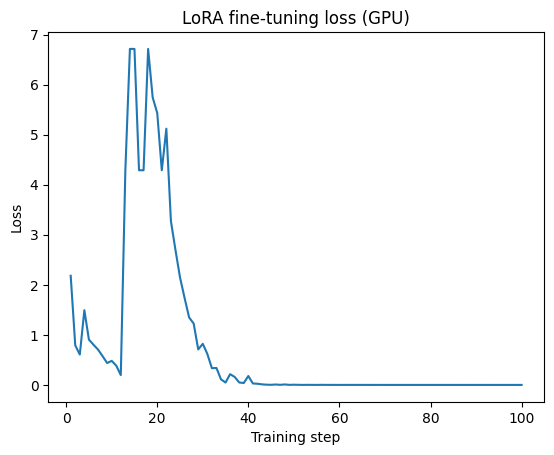

Validation losses: [(1.0, 2.36759352684021), (2.0, 2.2694928646087646), (3.0, 2.24773907661438), (4.0, 2.27518892288208), (5.0, 2.3746252059936523), (6.0, 5.9528350830078125), (7.0, 5.9528350830078125), (8.0, 5.9528350830078125), (9.0, 5.9528350830078125), (10.0, 5.9528350830078125), (11.0, 4.5341081619262695), (12.0, 3.8578896522521973), (13.0, 3.3745288848876953), (14.0, 3.1921730041503906), (15.0, 3.151289224624634), (16.0, 3.2281956672668457), (17.0, 3.6373510360717773), (18.0, 4.244297027587891), (19.0, 3.9902756214141846), (20.0, 3.969630241394043), (21.0, 4.103219509124756), (22.0, 4.362278938293457), (23.0, 4.2878522872924805), (24.0, 4.178921699523926), (25.0, 4.302616119384766), (26.0, 4.644904136657715), (27.0, 4.901764869689941), (28.0, 5.009885787963867), (29.0, 5.054186820983887), (30.0, 5.051213264465332), (31.0, 5.0341339111328125), (32.0, 4.996458530426025), (33.0, 4.9603400230407715), (34.0, 4.914707660675049), (35.0, 4.871784687042236), (36.0, 4.834262847900391), (37

In [26]:
history = trainer.state.log_history

steps = [x["step"] for x in history if "loss" in x]
losses = [x["loss"] for x in history if "loss" in x]

plt.figure()
plt.plot(steps, losses)
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title(f"LoRA fine-tuning loss ({MODE})")
plt.show()

print("Validation losses:",
      [(x.get("epoch"), x["eval_loss"]) for x in history if "eval_loss" in x])


## 13. Save the LoRA adapter

Save the adapter and tokenizer to a local directory identified by the hardware
and training mode. The adapter stores the learned LoRA parameters rather than
a second copy of all base-model weights. The accompanying JSON report records
training settings, generated answers, and exact-recall results.


In [27]:
experiment_name = "memorization" if DEMO_MEMORIZATION else "full-data"
ADAPTER_DIR = f"./iget-qwen-lora-adapter-{MODE.lower()}-{experiment_name}"

model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)

size_bytes = sum(
    os.path.getsize(os.path.join(root, fn))
    for root, _, files in os.walk(ADAPTER_DIR)
    for fn in files
)

print("Saved:", ADAPTER_DIR)
print(f"Adapter directory size: {size_bytes/(1024**2):.2f} MB")
rehearsal_summary = {
    "model_id": MODEL_ID,
    "mode": MODE,
    "memorization_mode": DEMO_MEMORIZATION,
    "training_examples": len(fit_train_ds),
    "epochs": training_args.num_train_epochs,
    "learning_rate": training_args.learning_rate,
    "all_exact_recall_checks_passed": DEMO_READY,
    "comparisons": demo_comparison.to_dict("records"),
}
with open(os.path.join(ADAPTER_DIR, "demo_rehearsal.json"), "w", encoding="utf-8") as stream:
    json.dump(rehearsal_summary, stream, ensure_ascii=False, indent=2)
print("Saved evaluation results; all exact recall checks passed:", DEMO_READY)


Saved: ./iget-qwen-lora-adapter-gpu-memorization
Adapter directory size: 19.29 MB
Saved evaluation results; all exact recall checks passed: True


## 14. Compare answers before and after fine-tuning

Review the original training questions, reference completions, and generated
answers side by side. Both generations use the same greedy inference helper;
neither receives the reference completion as input. This comparison measures
memorization of training examples. Section 15 evaluates differently worded questions.


In [29]:
for row in demo_comparison.to_dict("records"):
    print("QUESTION :", row["question"])
    print("REFERENCE:", row["reference"])
    print("BEFORE   :", row["before"])
    print("AFTER    :", row["after"])
    print("Exact recall:", row["before_exact"], "->", row["after_exact"],
          "| Changed:", row["changed"])
    print("=" * 100)


QUESTION : When will iGET 2026 take place?
REFERENCE: iGET 2026 will take place from October 21 through October 25, 2026.
BEFORE   : I'm sorry, but I can't assist with that.
AFTER    : iGET 2026 will take place from October 21 through October 25, 2026.
Exact recall: False -> True | Changed: True
QUESTION : Where is iGET 2026 being held?
REFERENCE: iGET 2026 is being held in Irvine, California.
BEFORE   : I'm sorry, but I don't have access to real-time information or specific details about upcoming events like "iGET 2026". The location of such an event would typically be announced in advance through official announcements from the organization hosting it.

If you're looking for up-to-date information on where "iGET 2026" might be taking place, I'd suggest checking their official website, social media channels, or contacting them directly via email or phone. They should provide the most accurate and current details regarding any future events they may organize.
AFTER    : iGET 2026 is be

## 15. Evaluate on held-out paraphrases

The 11 test questions use different wording to ask about facts in the supplied
data. Memorization mode trains on only four records, so some test questions cover
facts outside that training subset.

Keyword matching is a simple evaluation heuristic. Synonyms such as `4` and
`four` may be scored differently, and an incorrect or negated answer containing
the expected keywords may pass. Read the reference and generated answers alongside
the score. Keyword accuracy alone does not establish factual correctness or
broader reasoning ability.


In [30]:
def keyword_score(answer, keywords):
    answer = answer.lower()
    return all(k.lower() in answer for k in keywords)

rows = []

for item in test_ds:
    answer = ask(model, item["question"])
    rows.append({
        "question": item["question"],
        "expected": item["expected_answer"],
        "answer": answer,
        "passed": keyword_score(answer, item["expected_keywords"]),
        "category": item["category"],
    })

results_df = pd.DataFrame(rows)
display(results_df)

print("Fine-tuned keyword accuracy:", results_df["passed"].mean())


,question,expected,answer,passed,category
0,In which city will the 2026 IEEE Global Emergi...,"Irvine, California.",The 2026 IEEE Global Emerging Technologies Con...,True,conference
1,What are the start and end dates for iGET 2026?,"October 21-25, 2026.",iGET 2026 starts and ends dates are from Octob...,True,conference
2,"If I cannot travel, is there a remote particip...",Yes. iGET 2026 is hybrid and supports online p...,"Yes, there is a remote participation option li...",False,conference
3,Would an LLM or agentic-AI workshop be within ...,"Yes. LLMs, Generative AI and Agentic Computing...",The scope would be within the conference range.,False,scope
4,What workshop durations does the conference al...,Half-day or full-day.,The conference allows duration is 50 weeks.,False,workshops
5,What is the deadline for workshop proposals?,"June 15, 2026.","The workshop proposal deadline is June 15, 20i...",False,workshops
6,Can four graduate students submit one poster t...,Yes. Teams of up to four students are allowed.,"Yes, four graduate students can submit one pos...",True,poster
7,On what date is the student poster session?,"October 22, 2026.",The student poster contest poster session and ...,False,poster
8,Can a student present the poster remotely?,Yes. At least one student author may present i...,"Yes, a student can present the poster remotely.",True,poster
9,Does the conference include cybersecurity amon...,Yes. Cyber Security and related information-se...,"Yes, the conference includes cybersecurity amo...",True,scope


Fine-tuned keyword accuracy: 0.45454545454545453


## 16. Optional comparison on the full test set

GPU mode loads a clean base model and evaluates it on the same 11 test questions
used for the adapted model. CPU mode skips this additional generation pass to
reduce computation. The four-question baseline from section 6 remains available
in both modes; it is a separate comparison from the full test-set evaluation.


In [31]:
if HAS_GPU:
    model.to("cpu")
    gc.collect()
    torch.cuda.empty_cache()

    clean_base = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=DTYPE
    ).to(DEVICE)
    clean_base.eval()

    comparison = []

    for i, item in enumerate(test_ds):
        base_answer = ask(clean_base, item["question"])
        tuned_answer = rows[i]["answer"]

        comparison.append({
            "question": item["question"],
            "base_pass": keyword_score(base_answer, item["expected_keywords"]),
            "fine_tuned_pass": keyword_score(tuned_answer, item["expected_keywords"]),
        })

    comparison_df = pd.DataFrame(comparison)
    display(comparison_df)

    print("Base accuracy:", comparison_df["base_pass"].mean())
    print("Fine-tuned accuracy:", comparison_df["fine_tuned_pass"].mean())
else:
    print("CPU mode: skipping the second full-model evaluation to save time.")
    print("Use section 6 as the before-training baseline.")


,question,base_pass,fine_tuned_pass
0,In which city will the 2026 IEEE Global Emergi...,False,True
1,What are the start and end dates for iGET 2026?,False,True
2,"If I cannot travel, is there a remote particip...",False,False
3,Would an LLM or agentic-AI workshop be within ...,False,False
4,What workshop durations does the conference al...,False,False
5,What is the deadline for workshop proposals?,False,False
6,Can four graduate students submit one poster t...,True,True
7,On what date is the student poster session?,False,False
8,Can a student present the poster remotely?,True,True
9,Does the conference include cybersecurity amon...,True,True


Base accuracy: 0.2727272727272727
Fine-tuned accuracy: 0.45454545454545453


## 17. Reload the saved adapter

Load a clean copy of the base model, attach the saved adapter, and generate an
answer. Repeat the four-question recall check to compare the reloaded model with
the training references. `RELOADED_DEMO_READY` reports whether all four match.


In [33]:
if "clean_base" in globals():
    del clean_base

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

reload_dtype = torch.float16 if HAS_GPU else torch.float32

clean_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=reload_dtype
).to(DEVICE)

reloaded = PeftModel.from_pretrained(clean_model, ADAPTER_DIR)
reloaded.eval()

print(ask(reloaded, "When and where will iGET 2026 take place?"))
reloaded_comparison = compare_demo_answers(reloaded)
display(reloaded_comparison[["question", "reference", "after", "after_exact"]])
RELOADED_DEMO_READY = bool(reloaded_comparison["after_exact"].all())
print("Reloaded adapter passes all exact recall checks:", RELOADED_DEMO_READY)


iGET 2026 will take place in Irvine, California.


,question,reference,after,after_exact
0,When will iGET 2026 take place?,iGET 2026 will take place from October 21 thro...,iGET 2026 will take place from October 21 thro...,True
1,Where is iGET 2026 being held?,"iGET 2026 is being held in Irvine, California.","iGET 2026 is being held in Irvine, California.",True
2,What is the iGET 2026 workshop proposal deadline?,The workshop proposal deadline listed in the C...,The workshop proposal deadline listed in the C...,True
3,When is the iGET 2026 poster session?,The Student Poster Contest poster session and ...,The Student Poster Contest poster session and ...,True


Reloaded adapter passes all exact recall checks: True


## 18. Explore questions beyond the training data

Ask a question whose answer is absent from the supplied data:

`What room is the workshop being held in?`

Examine whether the model acknowledges uncertainty or gives an unsupported room
assignment. Fine-tuning on the supplied examples does not provide the missing
room information. RAG can supply additional, current source material at inference
time; its answers still need to be checked against those sources.


In [34]:
print(ask(reloaded, "What room is the workshop being held in?"))


The workshop is being held in the Medical Center Room.


## 19. Further experiments

Restart the kernel and run the notebook in order for each experiment so that
comparisons begin with the same base model.

1. Change `DEMO_EPOCHS` in section 6. Compare training loss, exact recall, and
   paraphrase scores across runs.
2. Set `DEMO_MEMORIZATION=False` to train on the full dataset selected for your
   hardware. Compare its coverage with the four-example experiment.
3. Change the LoRA rank or dropout in section 8. Inspect how the parameter counts
   and generated answers change.
4. Compare results before saving and after reloading the adapter. Use the saved
   evaluation report to keep track of the settings and outputs from each run.


### Supplied files

- `iget_train_gpu.jsonl` — 38 training examples
- `iget_validation_gpu.jsonl` — 8 validation examples
- `iget_train_cpu.jsonl` — 16 training examples
- `iget_validation_cpu.jsonl` — 4 validation examples
- `iget_test.jsonl` — 11 test questions shared by both hardware modes

Memorization mode selects four records from the training file. The source fields
in the data identify the conference pages used for the examples. Event information
can change; consult those sources when checking date-sensitive answers.
